# 08 坐标差异复核与FLAIR配对

恢复当前基线掩膜所对应48组检查中的FLAIR名称候选，进行全部切片技术检查，并复核既有12个掩膜网格差异。目录名称只是序列候选线索。坐标视野包含目标，不代表解剖对齐、无采集层间隙或配准已成功。原有0.001体素网格标准保持不变。

In [1]:
from pathlib import Path
import sys,json,gzip,runpy,hashlib
import pandas as pd
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
raw=gzip.decompress((ROOT/'data/metadata/baseline_qc/flair_series_members.jsonl.gz').read_bytes())
assert len(raw.decode().splitlines())==1391
print('FLAIR manifest SHA256:',hashlib.sha256(raw).hexdigest())
qc=runpy.run_path(str(ROOT/'scripts/audit_additional_imaging.py'))['run']
flair_qc=qc(manifest_relative='data/metadata/baseline_qc/flair_series_members.jsonl',prefix='flair',output_subdir='flair-grid-qc-20261028',scope='all named non-T1 FLAIR candidates in 48 baseline mask studies',write_overlays=False,include_mask_audit=False)
assert flair_qc['mask_audit_performed'] is False
assert flair_qc['integrity_verified_files']==flair_qc['pixel_decodable_files']==1391

FLAIR manifest SHA256: b078376f9c79cba263897587acf60ecf26e97d86fcb6a2b42500033e6c307190
{
  "scope": "all named non-T1 FLAIR candidates in 48 baseline mask studies",
  "studies": 40,
  "dicom_files": 1391,
  "series_uid_groups": 40,
  "series_directories": 40,
  "integrity_verified_files": 1391,
  "pixel_decodable_files": 1391,
  "nonfinite_pixel_arrays": 0,
  "constant_pixel_arrays": 0,
  "date_mismatch_files": 0,
  "duplicate_sop_files": 0,
  "regular_geometry_stacks": 40,
  "technical_pass_stacks": 40,
  "t2_flair_metadata_candidates": 40,
  "t1_flair_names_not_t2_flair": 0,
  "derived_or_projection_groups": 0,
  "spacing_tag_position_mismatch_groups": 0,
  "t2_flair_candidates_with_interslice_gap": 38,
  "contrast_bolus_tag_populated_files": 0,
  "engineering_tolerances": {
    "direction_or_spacing_abs": 0.0001,
    "duplicate_plane_mm": 0.001,
    "plane_step_abs_mm": 0.05,
    "plane_step_relative": 0.01,
    "affine_residual_mm": 0.1,
    "grid_corner_voxels": 0.001
  },
  "man

## 12个病灶的NIfTI坐标复核

分别比较qform与sform，以及二者与DICOM网格的全体积角点差异。比较首、末平面及层间步长，记录较接近的一端。端点模式可以支持转换精度假设，但不能确定真实转换流程；未经证据确认，不替换仿射或修改标签。

In [2]:
summary=runpy.run_path(str(ROOT/'scripts/audit_grid_precision_and_flair_pairs.py'))['run']()
r=pd.read_csv(ROOT/'data/processed/grid_precision_review.csv')
print(r[['lesion_key','qform_sform_corner_difference_mm','sform_dicom_corner_difference_mm','qform_dicom_corner_difference_mm','closer_anchor','nearest_end_pair_step_difference_mm']].to_string(index=False))
assert len(r)==12
assert r.review_resolved.sum()==r.source_header_changed.sum()==r.resampling_performed.sum()==0

{
  "grid_review_lesions": 12,
  "grid_review_unique_masks": 10,
  "qform_alone_resolves_grid_discrepancy": 2,
  "max_qform_sform_corner_difference_mm": 0.013295671168264528,
  "max_sform_dicom_corner_difference_mm": 0.104119129855043,
  "closer_last_plane": 9,
  "closer_first_plane": 3,
  "resolved_grid_reviews": 0,
  "unchanged_strict_grid_equivalent_lesions": 42,
  "baseline_lesions": 54,
  "baseline_studies": 48,
  "lesions_with_named_flair": 46,
  "lesions_without_named_flair": 8,
  "flair_series": 40,
  "flair_files": 1391,
  "studies_with_named_flair": 40,
  "paired_all_target_centers_inside_coordinate_fov": 45,
  "paired_partial_coordinate_fov": 1,
  "frame_uid_comparison_counts": {
    "identical_single_uid": 46
  },
  "fov_interpretation": "coordinate extent only; not anatomical alignment, slice-gap coverage or validated registration",
  "registration_performed": false,
  "source_headers_changed": false,
  "labels_changed": false,
  "models_fitted": false,
  "input_sha256": {

## FLAIR技术检查与层间隙

按同日、同患者配对，保留所有FLAIR名称候选。头信息中的对比剂字段为空时不能补成未给药；名称含GADO/GD等只保留提示。层间隙是切片厚度与中心间距的关系，不按文件缺失处理。

In [3]:
s=pd.read_csv(ROOT/'data/processed/flair_dicom_series_qc.csv')
print(s[['patient_id','study_date_code','series_name','files','SliceThickness','slice_step_mm','interslice_gap_present','EchoTime','InversionTime','technical_stack_pass']].to_string(index=False))
assert len(s)==40
assert s.files.sum()==1391
print('Recorded acquisition slice gaps:',int(s.interslice_gap_present.sum()))

 patient_id  study_date_code             series_name  files  SliceThickness  slice_step_mm  interslice_gap_present  EchoTime  InversionTime  technical_stack_pass
      10005         19020128            FLAIR_longTR     25             5.5       6.500000                       1   140.000        2800.00                     1
      10029         19030605 3D_Brain_VIEW_FLAIR_Tra    236             1.2       0.600000                       0   352.791        1660.00                     1
      10033         19000918 3D_Brain_VIEW_FLAIR_Tra    236             1.2       0.600002                       0   355.510        1660.00                     1
      10038         19001015           eFLAIR_longTR     30             5.0       6.000000                       1   140.000        2800.00                     1
      20034         19000729     eCOR_FLAIR_T2_SENSE     32             4.0       4.400000                       1   125.000        2800.00                     1
      40001         19000101

## 配对与坐标视野

先比较StudyInstanceUID、FrameOfReferenceUID，再将原掩膜的体素中心转换到FLAIR连续网格，统计是否处于坐标范围内。这不是图像配准或病灶定位验证；相同UID也不能排除头动。未找到FLAIR名称候选的检查保留为缺失，不用T1重建序列替代。

In [4]:
p=pd.read_csv(ROOT/'data/processed/baseline_flair_pairs.csv')
print(p[['lesion_key','flair_candidate_found','flair_series_name','FrameOfReferenceUID_comparison','coordinate_fov_fraction','flair_interslice_gap_present']].to_string(index=False))
assert p.lesion_key.nunique()==54
assert p.use_for_model.sum()==p.registration_performed.sum()==0
print('Missing FLAIR lesion candidates:',p.loc[p.flair_candidate_found==0,'lesion_key'].tolist())
runpy.run_path(str(ROOT/'scripts/review_partial_flair_fov.py'))['run']()
from IPython.display import Image,display
display(Image(filename=str(ROOT/'outputs/flair-grid-qc-20261028/40158_L1_native_fov_review.png')))

lesion_key  flair_candidate_found       flair_series_name FrameOfReferenceUID_comparison  coordinate_fov_fraction  flair_interslice_gap_present
  10005_L1                      1            FLAIR_longTR           identical_single_uid                    1.000                           1.0
  10029_L2                      1 3D_Brain_VIEW_FLAIR_Tra           identical_single_uid                    1.000                           0.0
  10033_L2                      1 3D_Brain_VIEW_FLAIR_Tra           identical_single_uid                    1.000                           0.0
  10038_L1                      1           eFLAIR_longTR           identical_single_uid                    1.000                           1.0
  10046_L1                      0                     NaN                            NaN                      NaN                           NaN
  20034_L1                      1     eCOR_FLAIR_T2_SENSE           identical_single_uid                    1.000                       

## 当前研究状态

既有42个严格网格匹配、12个待复核状态保持。本文不将亚体素差异自动定义为分割错误或临床可接受。完成FLAIR恢复和几何审阅后，仍需序列类型、空间配准及临床图像质量审阅。结局证据仍未补足，暂不拟合风险模型。

依据：[NiBabel NIfTI坐标选择](https://nipy.org/nibabel/nifti_images.html)、[NIfTI qform/sform规范](https://nifti.nimh.nih.gov/nifti-1/documentation/nifti1fields/nifti1fields_pages/qsform.html/document_view.html)。

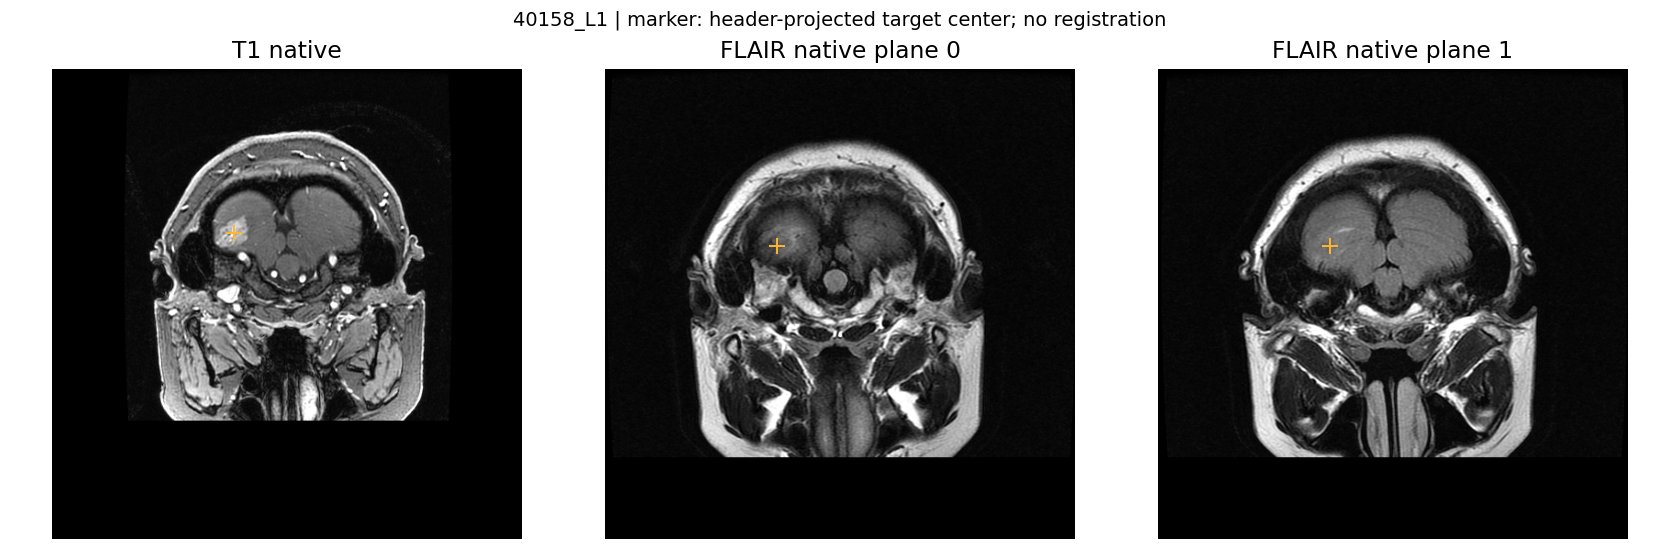

No labels, source affines or model eligibility changed.


In [5]:
c=pd.read_csv(ROOT/'data/processed/clinical_current.csv')
assert c.rn_time_day.isna().sum()==125
assert c.verified_non_event.sum()==0
assert summary['resolved_grid_reviews']==0
assert summary['registration_performed'] is False
assert summary['models_fitted'] is False
print('No labels, source affines or model eligibility changed.')